# Proyek Big Data: Web Scraping & Analisis Sentimen Komentar Facebook Reel
**Nama Mahasiswa:** Hadianto Rasyid  
**Target URL:** [Facebook Reel - Hadianto Rasyid](https://www.facebook.com/share/r/1ComAvy19T/)  
**Tujuan:** Mengambil metadata video/reel Facebook, mengekstrak komentar audiens menggunakan Selenium WebDriver, melakukan preprocessing teks (data cleaning), analisis frekuensi kata, dan klasifikasi analisis sentimen (Positif, Netral, Negatif).

## 1. Instalasi dan Import Library

In [1]:
# Jalankan perintah berikut jika library belum terpasang di environment Anda
# !pip install selenium pandas beautifulsoup4 matplotlib seaborn openpyxl

In [2]:
import os
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Import modul scraper dan analyzer lokal
from facebook_scraper import FacebookScraper
from analyze_comments import FacebookCommentAnalyzer

print("Semua library dan modul berhasil dimuat!")

Semua library dan modul berhasil dimuat!


## 2. Eksekusi Web Scraping Facebook Reel

In [3]:
TARGET_URL = "https://www.facebook.com/share/r/1ComAvy19T/"

# Inisialisasi scraper Facebook dengan pagination otomatis
scraper = FacebookScraper(url=TARGET_URL, max_comments=150, max_clicks=20, headless=True)
scraped_data = scraper.run()

# Ekspor hasil ke format JSON dan CSV
scraper.export_to_json("facebook_scraped_data.json")
scraper.export_to_csv("facebook_comments.csv", "facebook_metadata.csv")
print(f"Total komentar berhasil diambil: {len(scraped_data['comments'])}")

2026-11-20 12:29:55,798 [INFO] Membuka browser & menavigasi ke: https://www.facebook.com/share/r/1ComAvy19T/
2026-11-20 12:30:09,887 [INFO] Pop-up / dialog login Facebook berhasil ditutup.
2026-11-20 12:30:12,214 [INFO] Metadata berhasil diambil: 221 rb tayangan · 85 rb tanggapan | Masih jadi pertanyaan kenapa yang terakhir itu ba sembunyi dia 😄 | Hadianto Rasyid | Hadianto Rasyid
2026-11-20 12:30:12,216 [INFO] Memulai pengambilan komentar (Target: ~150 komentar)...
2026-11-20 12:30:12,961 [INFO] Klik 'Lihat komentar' ke-1 sukses.
2026-11-20 12:30:15,640 [INFO] Klik 'Lihat komentar' ke-2 sukses.
2026-11-20 12:30:18,329 [INFO] Klik 'Lihat komentar' ke-3 sukses.
2026-11-20 12:30:21,010 [INFO] Klik 'Lihat komentar' ke-4 sukses.
2026-11-20 12:30:23,720 [INFO] Klik 'Lihat komentar' ke-5 sukses.
2026-11-20 12:30:26,392 [INFO] Klik 'Lihat komentar' ke-6 sukses.
2026-11-20 12:30:29,128 [INFO] Klik 'Lihat komentar' ke-7 sukses.
2026-11-20 12:30:31,827 [INFO] Klik 'Lihat komentar' ke-8 sukses.
2

Total komentar berhasil diambil: 152


## 3. Eksplorasi Metadata Video / Reel

In [4]:
df_meta = pd.read_csv("facebook_metadata.csv")
display(df_meta)

,title,page_name,views,reactions,url,canonical_url,platform,scraped_at
0,221 rb tayangan · 85 rb tanggapan | Masih jadi...,Hadianto Rasyid,"5,4 jt Tayangan",85 rb,https://www.facebook.com/share/r/1ComAvy19T/,https://web.facebook.com/halamanhadiantorasyid...,Facebook Reels / Video,2026-11-20 12:30:12


## 4. Membaca & Menampilkan Data Komentar

In [5]:
df_comments = pd.read_csv("facebook_comments.csv")
print(f"Total komentar yang dimuat: {len(df_comments)}")
display(df_comments.head(10))

Total komentar yang dimuat: 152


,author,text,like_count,timestamp
0,Firman Bansel,Bapaknya anak anak kota palu ini,84,30 minggu
1,Riryn Rahayu,Adoo pak wali yang tapele tembok itu bgmn kaba...,260,32 minggu
2,Asriadhy Asriadhy,Sy tidak di ajak pak??,239,32 minggu
3,Hasan Santos,Tidak ada bosannya saya melihat video ini. Tam...,117,29 minggu
4,Kaival,Sampai sekarang kabar teman yg di balik tembox...,45,27 minggu
5,Acik Bae,Ini bukan di pencitraan dari gaya bicaranya aj...,19,28 minggu
6,Dadang Papzmj,itu yg di balik tembok adalah ceo yg menyembun...,60,32 minggu
7,Riyan Batik,Memang ini walikota,30,32 minggu
8,Putu Sandya,Yg sembunyi di tembok lupa petunjuk kayaknya b...,25,29 minggu
9,Sunny Nadine,Terserah bapak Jo,7,32 minggu


## 5. Pembersihan Data & Analisis Sentimen

In [6]:
analyzer = FacebookCommentAnalyzer("facebook_comments.csv")
stats = analyzer.compute_summary_statistics()
analyzer.export_analysis_results()
analyzer.export_to_sqlite()

# Tampilkan DataFrame hasil pembersihan teks dan label sentimen
df_clean = pd.read_csv("cleaned_facebook_comments.csv")
display(df_clean[["author", "cleaned_text", "like_count", "sentiment"]].head(10))

2026-11-20 12:31:01,345 [INFO] Memuat data dari: facebook_comments.csv
2026-11-20 12:31:01,427 [INFO] Berhasil memuat 152 baris data komentar Facebook.
2026-11-20 12:31:01,429 [INFO] Menjalankan proses pembersihan teks (Data Cleaning)...
2026-11-20 12:31:01,442 [INFO] Pembersihan data dan klasifikasi sentimen selesai.
2026-11-20 12:31:01,463 [INFO] Dataset hasil pembersihan tersimpan di: D:\semester 5\BIG DATA\SCRIPING HADIANTO RASYID\cleaned_facebook_comments.csv
2026-11-20 12:31:01,466 [INFO] Ringkasan analitik tersimpan di: D:\semester 5\BIG DATA\SCRIPING HADIANTO RASYID\comments_analysis_summary.json
2026-11-20 12:31:01,497 [INFO] Data (152 baris) berhasil disimpan ke SQLite DB: 'facebook_bigdata.db' (Tabel: 'comments')


,author,cleaned_text,like_count,sentiment
0,Firman Bansel,bapaknya anak anak kota palu ini,84,Netral
1,Riryn Rahayu,adoo pak wali yang tapele tembok itu bgmn kaba...,260,Netral
2,Asriadhy Asriadhy,sy tidak di ajak pak,239,Netral
3,Hasan Santos,tidak ada bosannya saya melihat video ini tamp...,117,Positif
4,Kaival,sampai sekarang kabar teman yg di balik tembox...,45,Netral
5,Acik Bae,ini bukan di pencitraan dari gaya bicaranya aj...,19,Netral
6,Dadang Papzmj,itu yg di balik tembok adalah ceo yg menyembun...,60,Netral
7,Riyan Batik,memang ini walikota,30,Netral
8,Putu Sandya,yg sembunyi di tembok lupa petunjuk kayaknya b...,25,Netral
9,Sunny Nadine,terserah bapak jo,7,Netral


## 6. Visualisasi Data (EDA & Distribusi Sentimen)

C:\Users\ACER\AppData\Local\Temp\ipykernel_18316\4219453339.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_words, x="frequency", y="word", palette="viridis", ax=axes[1])


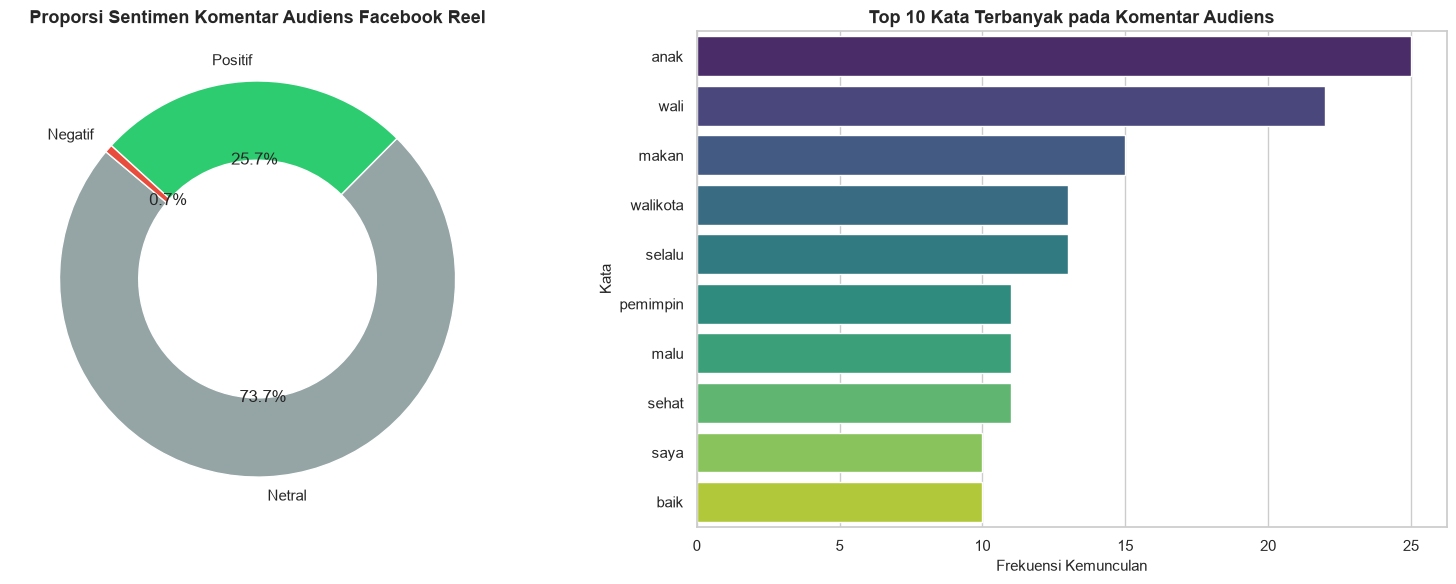

In [7]:
# Set tema visualisasi
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Visualisasi Distribusi Sentimen (Donut Chart)
sentiment_counts = df_clean["sentiment"].value_counts()
colors = {"Positif": "#2ecc71", "Netral": "#95a5a6", "Negatif": "#e74c3c"}
plot_colors = [colors.get(s, "#3498db") for s in sentiment_counts.index]

axes[0].pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=140,
    colors=plot_colors,
    wedgeprops=dict(width=0.4, edgecolor="w")
)
axes[0].set_title("Proporsi Sentimen Komentar Audiens Facebook Reel", fontsize=13, fontweight="bold")

# 2. Visualisasi Top 10 Kata Terbanyak (Bar Chart)
top_words = pd.DataFrame(stats["top_20_frequent_words"]).head(10)
sns.barplot(data=top_words, x="frequency", y="word", palette="viridis", ax=axes[1])
axes[1].set_title("Top 10 Kata Terbanyak pada Komentar Audiens", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Frekuensi Kemunculan", fontsize=11)
axes[1].set_ylabel("Kata", fontsize=11)

plt.tight_layout()
plt.show()